In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn import set_config
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

set_config(display="text")

Завантажимо датасет Phishing URL Detection (https://www.kaggle.com/datasets/sahandnamvar/phishing-url-detection-111k-urls-22-features), що містить 111 660 унікальних URL-адрес, серед яких 100 000 є безпечними, тоді як 11 660 - фішинговими.

In [2]:
df = pd.read_csv("URLDataset.csv")

Колонки датасета поділяються на:

*   Посилання (url)
*   Домен (dom)
*   Домен верхнього рівня (tld)
*   Відповідні довжини (url_len, dom_len, tld_len, path_len, query_len)
*   Лічильники символів (letter_cnt, digit_cnt, special_cnt, eq_cnt, qm_cnt, amp_cnt, dot_cnt, dash_cnt, under_cnt, slash_cnt, subdom_cnt)
*   Відповідні частки (letter_ratio, digit_ratio, spec_ratio)
*   Ентропію (entropy)
*   Бінарні ознаки (is_ip, is_https)
*   Цільова змінна (label)

Кожне посилання містить 22 числові ознаки, зокрема довжина URL, довжина домену, кількість піддоменів, ентропія та використання протоколу HTTPS.

In [3]:
df.columns

Index(['url', 'url_len', 'dom', 'dom_len', 'is_ip', 'tld', 'tld_len',
       'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt',
       'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio',
       'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy',
       'path_len', 'query_len', 'label'],
      dtype='object')

Датасет складається з 116 600 рядків та 26 колонок.

In [4]:
df.shape

(116600, 26)

In [5]:
df.head()

,url,url_len,dom,dom_len,is_ip,tld,tld_len,subdom_cnt,letter_cnt,digit_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,https://www.rmit.edu.au/,24,rmit.edu.au,11,0,edu.au,6,1,17,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,http://www.latrobe.edu.au/,26,latrobe.edu.au,14,0,edu.au,6,1,19,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,https://www.cqu.edu.au/,23,cqu.edu.au,10,0,edu.au,6,1,16,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,http://bond.edu.au/,19,bond.edu.au,11,0,edu.au,6,0,13,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,http://www.csu.edu.au/,22,csu.edu.au,10,0,edu.au,6,1,15,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


Датасет складається з текстових (url, dom, tld) та числових (url_len, dom_len, tld_len, path_len, query_len, letter_cnt, digit_cnt, special_cnt, eq_cnt, qm_cnt, amp_cnt, dot_cnt, dash_cnt, under_cnt, slash_cnt, subdom_cnt, letter_ratio, digit_ratio, spec_ratio, entropy), серед яких три колонки містять бінарні значення (is_ip, is_https, label).

In [6]:
df.dtypes

,0
url,object
url_len,int64
dom,object
dom_len,int64
is_ip,int64
tld,object
tld_len,int64
subdom_cnt,int64
letter_cnt,int64
digit_cnt,int64


In [7]:
df = df.drop(columns=["url", "dom", "tld"])

Перевірка df.isnull().sum() показала 0 пропущених значень у всіх колонках, тому заповнення чи видалення не потрібне.

In [8]:
df.isnull().sum()

,0
url_len,0
dom_len,0
is_ip,0
tld_len,0
subdom_cnt,0
letter_cnt,0
digit_cnt,0
special_cnt,0
eq_cnt,0
qm_cnt,0


Також було знайдено знайдено та видалено 62 183 дублікати.

In [9]:
df.duplicated().sum()

np.int64(62183)

In [10]:
df = df.drop_duplicates()

In [11]:
df.columns

Index(['url_len', 'dom_len', 'is_ip', 'tld_len', 'subdom_cnt', 'letter_cnt',
       'digit_cnt', 'special_cnt', 'eq_cnt', 'qm_cnt', 'amp_cnt', 'dot_cnt',
       'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'spec_ratio',
       'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len', 'label'],
      dtype='object')

У результаті обробки датасет складається з 54 417 рядків та 23 колонок.

In [11]:
df.shape

(54417, 23)

In [12]:
df.head()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,24,11,0,6,1,17,0,7,0,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,26,14,0,6,1,19,0,7,0,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,23,10,0,6,1,16,0,7,0,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,19,11,0,6,0,13,0,6,0,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,22,10,0,6,1,15,0,7,0,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


In [13]:
df.describe()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
count,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,...,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000
mean,42.663028,13.717294,0.000221,3.425988,0.886561,32.699083,1.860816,8.103130,0.165739,0.078358,...,0.113770,0.765087,0.023317,0.211595,0.517136,3.509289,4.030527,11.985538,3.380580,0.237242
std,40.364562,5.813590,0.014848,1.607535,0.538245,30.584913,8.481261,5.503192,0.707213,0.280710,...,0.701191,0.067823,0.062496,0.052026,0.499711,1.223270,0.406561,24.234633,28.088924,0.425396
min,12.000000,4.000000,0.000000,0.000000,0.000000,4.000000,0.000000,4.000000,0.000000,0.000000,...,0.000000,0.144928,0.000000,0.012998,0.000000,2.000000,2.653544,0.000000,0.000000,0.000000
25%,27.000000,10.000000,0.000000,2.000000,1.000000,20.000000,0.000000,6.000000,0.000000,0.000000,...,0.000000,0.733333,0.000000,0.173913,0.000000,3.000000,3.794167,1.000000,0.000000,0.000000
50%,34.000000,12.000000,0.000000,3.000000,1.000000,26.000000,0.000000,7.000000,0.000000,0.000000,...,0.000000,0.774194,0.000000,0.210526,1.000000,3.000000,3.989898,3.000000,0.000000,0.000000
75%,43.000000,17.000000,0.000000,4.000000,1.000000,34.000000,0.000000,9.000000,0.000000,0.000000,...,0.000000,0.810811,0.000000,0.250000,1.000000,4.000000,4.183465,14.000000,0.000000,0.000000
max,1202.000000,62.000000,1.000000,22.000000,7.000000,1037.000000,321.000000,234.000000,29.000000,17.000000,...,20.000000,0.936000,0.826087,0.523810,1.000000,37.000000,6.032729,670.000000,1148.000000,1.000000


Heatmap кореляцій показує залежності між відповідними числовими ознаками. Групи ознак з довжинами та лічильниками (наприклад, url_len, letter_cnt, digit_cnt) сильно корелюють між собою, оскільки всі зростають із довжиною URL. letter_ratio, digit_ratio та spec_ratio корелюють між собою негативно, тоді як кореляція окремих ознак із цільовою змінною (label) помірна або слабка, що свідчить про неможливість розподілу на класи за однією ознакою.

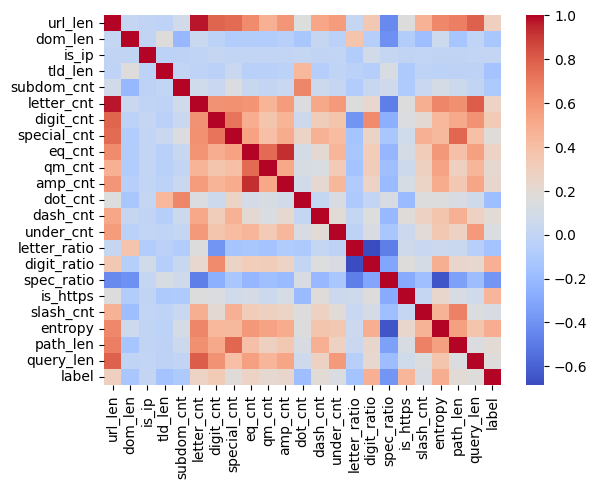

In [14]:
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.show()

Гістограми визначають, що url_len, letter_cnt та tld_len мають різко скошені розподіли, що свідчить про велику кільість коротких URL-адрес. Ознака letter_ratio скошений вліво, тоді як entropy близька до нормального розподілу з центром біля 4.

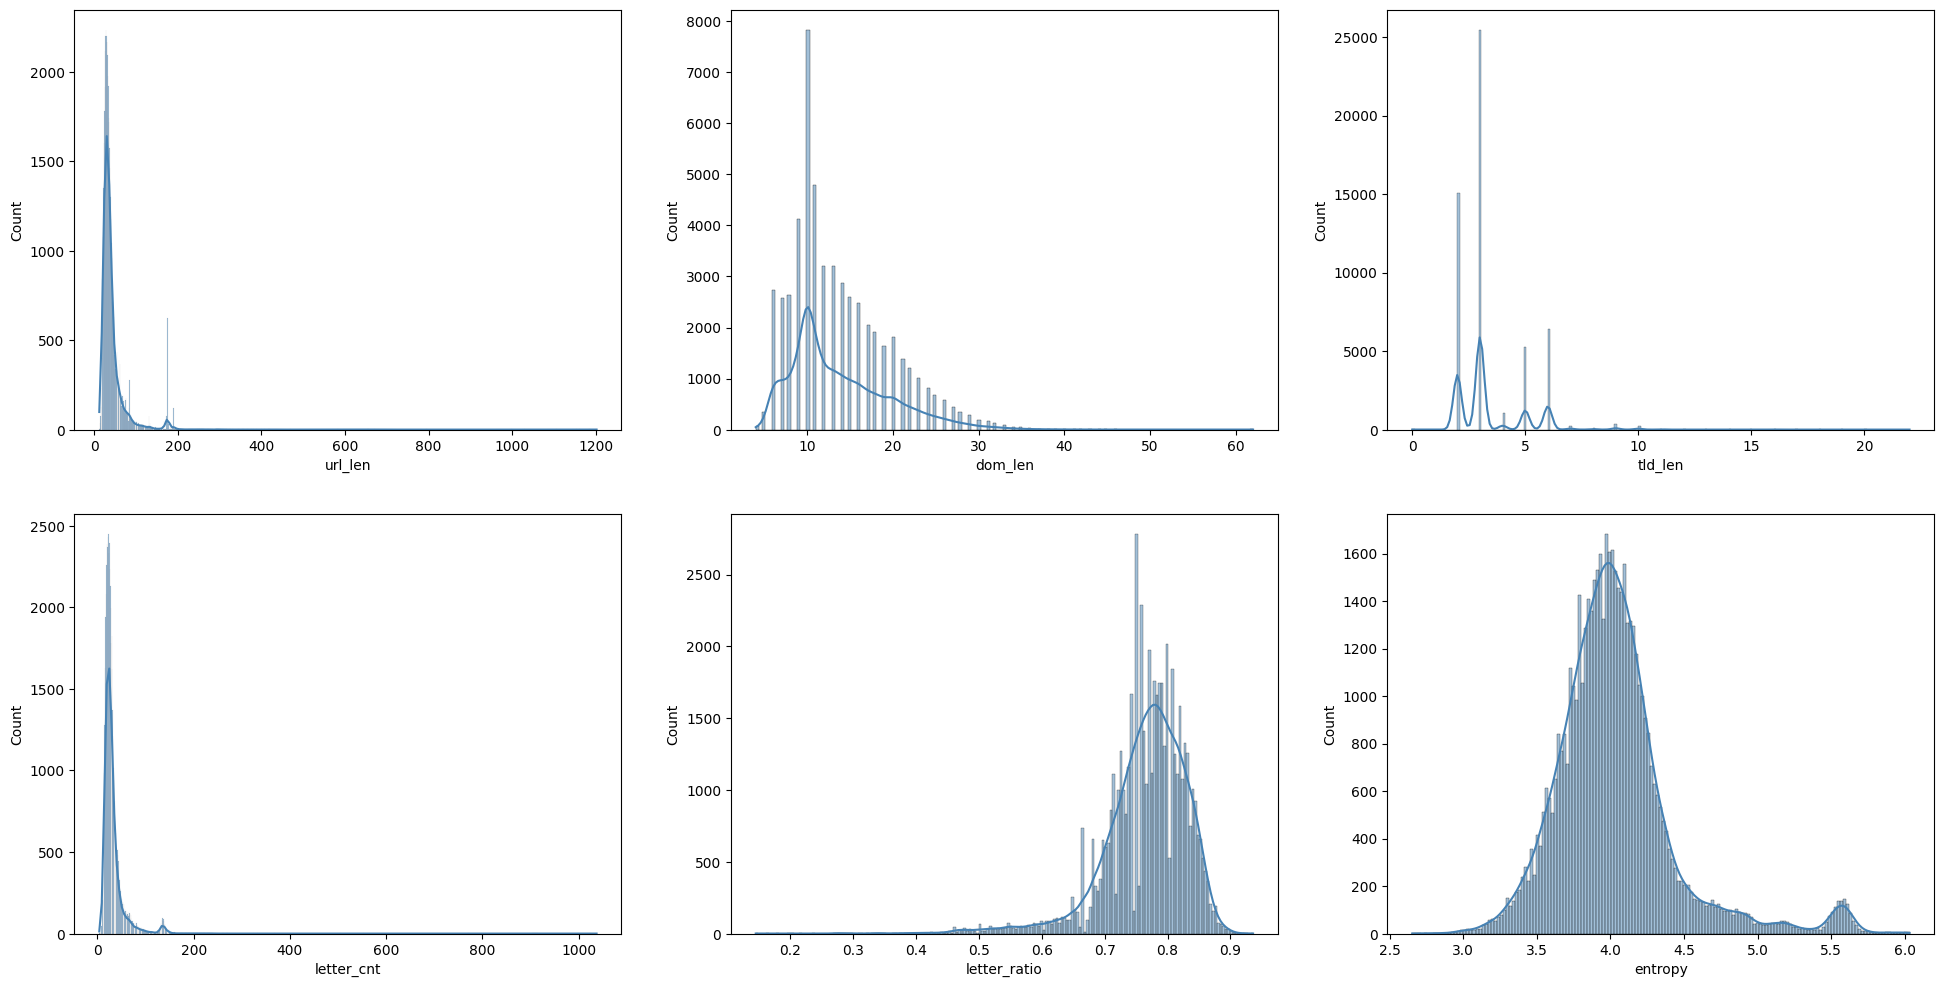

In [16]:
n_cols = 3

top_features = ["url_len", "dom_len", "tld_len", "letter_cnt", "letter_ratio", "entropy"]
n_rows = int(np.ceil(len(top_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 6 * n_rows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(top_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")

for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

Boxplot відносно label показують, що фішингові URL мають більше викидів за довжиною, а їхня ентропія в середньому вища. Довжина домену верхнього рівня (tld_len) у фішингових посиланнях майже константна, тоді як у безпечних сайтів розкид більший.

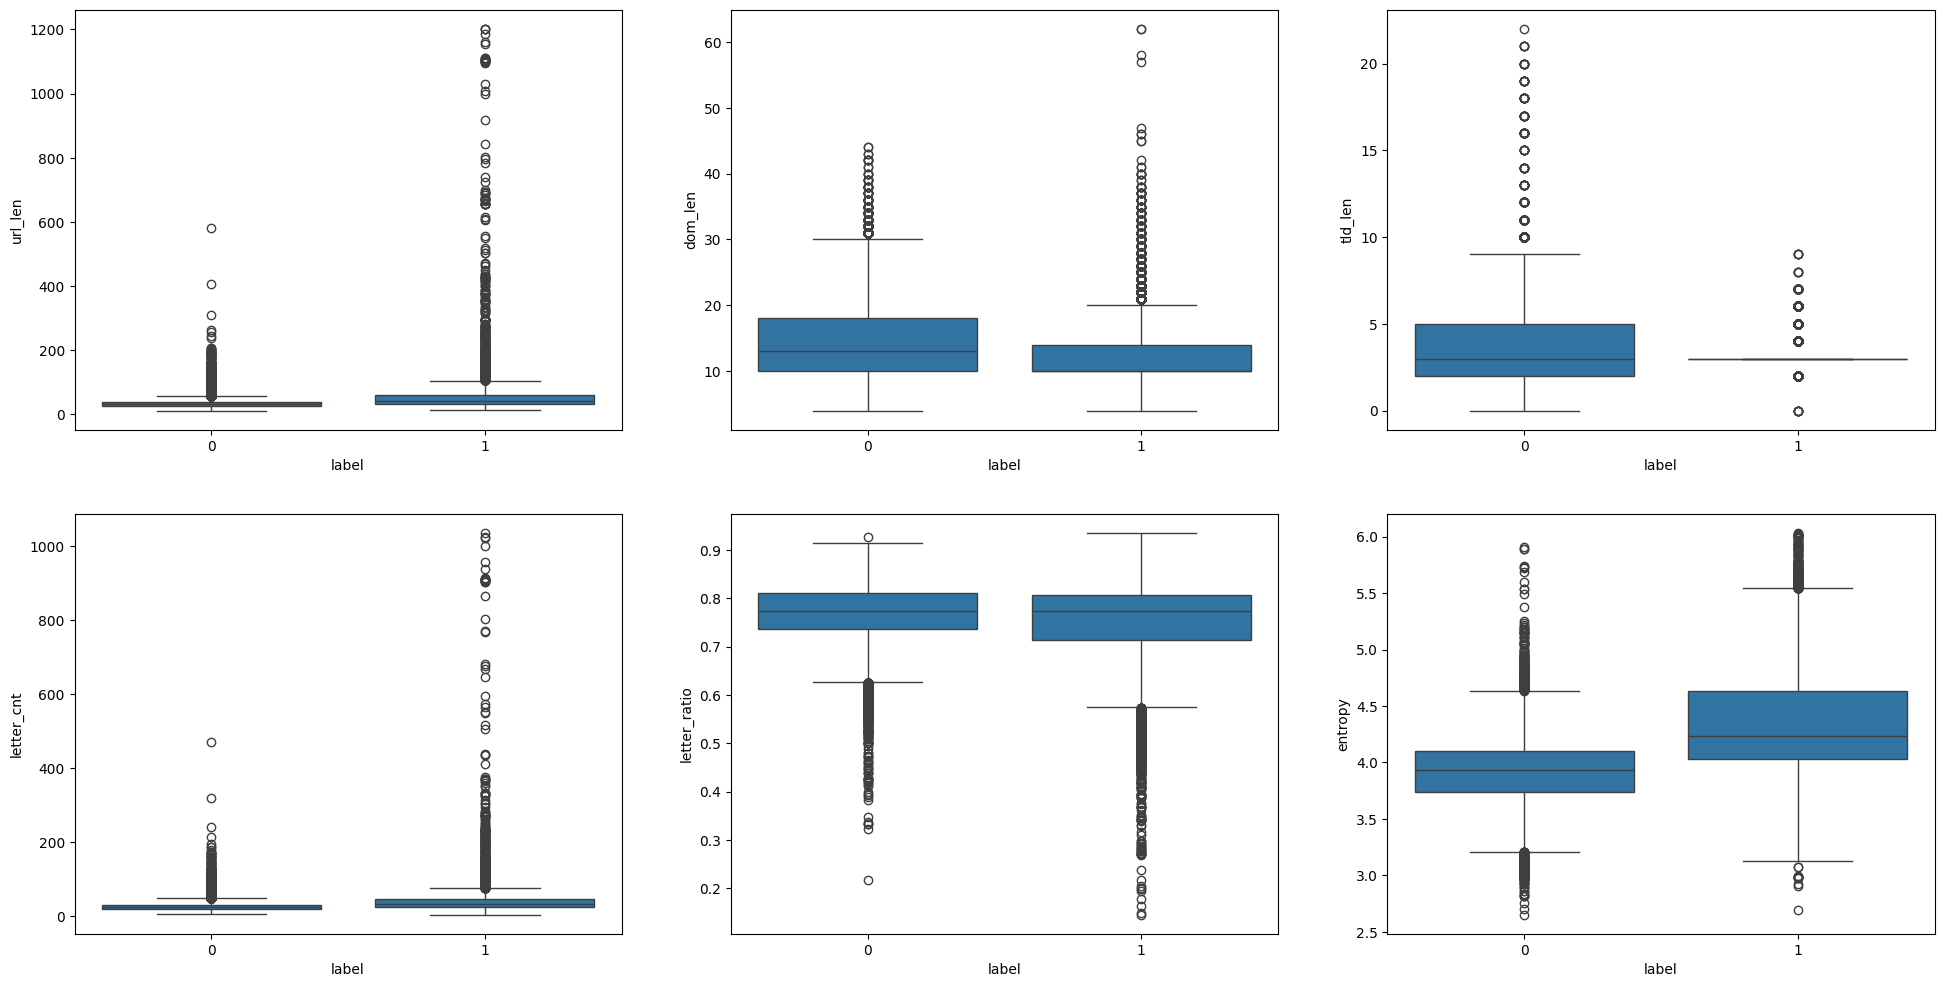

In [17]:
n_cols = 3

top_features = ["url_len", "dom_len", "tld_len", "letter_cnt", "letter_ratio", "entropy"]
n_rows = int(np.ceil(len(top_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 6 * n_rows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(top_features):
    sns.boxplot(x=df["label"], y=df[col], ax=axes[i])

for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

Після очищення було визначено 41 507 безпечних (76,28%) та 12 910 фішингових (23,72%) посилання. Фінальні класи незбалансовані, тому крім accuracy (точність) основною метрикою обрано F1 (враховує як влучність (precision), так і повноту (recall)) для фішингу, оскільки accuracy може бути високою навіть у моделі, яка погано знаходить фішинг.

In [18]:
phishing_urls_count = df["label"].value_counts()
phishing_urls_ratio = df["label"].value_counts(normalize=True) * 100
for item in phishing_urls_count.index:
  print(f"{phishing_urls_count[item]} {'фішингових' if item == 1 else 'безпечних'} посилань ({phishing_urls_ratio[item]:.2f}%)")

41507 безпечних посилань (76.28%)
12910 фішингових посилань (23.72%)


In [19]:
X = df.drop(["label"], axis = 1)
y = df["label"]

In [20]:
print(X.shape, y.shape)

(54417, 22) (54417,)


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

У результаті розбиття отримано 43 533 тренувальних та 10 884 тестових об'єкти. Значення random_state забезпечує відтворюваність, тоді як stratify=y зберігає однакове співвідношення класів у train та test вибірках, що важливо при незбалансованості.

In [22]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(43533, 22) (43533,)
(10884, 22) (10884,)


Масштабування виконується лише на train вибірці, тоді як на test застосовується transform для того, щоб інформація з тестових даних не потрапила в навчання.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Масштабування потрібне для kNN і SVM, оскільки зазначені моделі залежать від відстаней між точками. У обраному датасеті ознаки мають різні діапазони, тому без масштабування великі за значенням ознаки домінуватимуть. Моделі Decision Tree, Random Forest та AdaBoost працюють із порогами окремих ознак, тому масштаб для них не важливий.

# **k-Nearest Neighbors (kNN)**

Оптимальну кількість сусідів підберемо перебором k від 1 до 30 за допомогою 5-кратної крос-валідації з оцінкою за F1.

In [24]:
k_values = range(1, 31)
knn_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    cross_val = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring="f1")
    knn_scores.append(cross_val.mean())

Найкраще значення k = 5, оскільки для малих k модель перенавчається на шумі, тоді як для великих втрачає здатність точно враховувати відмінності між різними класами, тому показник F1 спадає.

Text(0, 0.5, 'F1 Score')

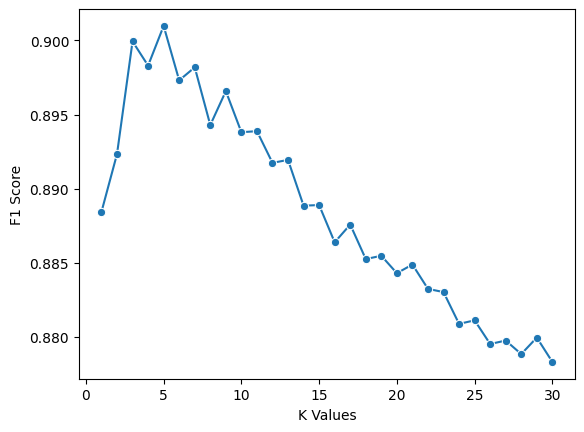

In [25]:
sns.lineplot(x = k_values, y = knn_scores, marker = 'o')
plt.xlabel("K Values")
plt.ylabel("F1 Score")

In [26]:
best_k = k_values[int(np.argmax(knn_scores))]
print(best_k)

5


На тестовій вибірці модель показала accuracy 0.95, precision для фішингу 0.92, recall=0.87 та F1=0.90.

In [27]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      8302
           1       0.92      0.87      0.90      2582

    accuracy                           0.95     10884
   macro avg       0.94      0.92      0.93     10884
weighted avg       0.95      0.95      0.95     10884



З матриці помилок видно, що безпечні URL розпізнаються дуже добре, оскільки лише 204 з 8 302 помилково визначені фішинговими.Водночас із 2 582 фішингових адрес знайдено 2 257, тоді як 325 пропущено. Нижчий recall фішингу порівняно з безпечними адресами пояснюється тим, що фішинг становить меншу кількість, тоді як модель kNN обирає класи з більшою кількістю сусідів.

In [28]:
print(confusion_matrix(y_test, y_pred))

[[8098  204]
 [ 325 2257]]


# **Decision Tree**

Для моделі Decision Tree введемо обмеження глибини (max_depth = 10) та мінімального розміру листка (min_samples_leaf = 2) для захисту від перенавчання.

In [29]:
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,
    min_samples_leaf=2,
    random_state=42
)

In [30]:
tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, random_state=42)

In [31]:
y_pred = tree.predict(X_test)

На тестовій вибірці дерево показало accuracy 0.94, precision для фішингу 0.90, recall=0.84 та F1=0.87.

In [32]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      8302
           1       0.90      0.84      0.87      2582

    accuracy                           0.94     10884
   macro avg       0.92      0.90      0.91     10884
weighted avg       0.94      0.94      0.94     10884



Матриця помилок визначила, що правильно класифіковано 10 222 об'єкти, тоді як помилок 662, з яких 242 є хибними тривогами (FP), а 420 є пропущеним фішингом (FN).

In [33]:
print(confusion_matrix(y_test, y_pred))

[[8060  242]
 [ 420 2162]]


Візуалізація дерева до глибини 3 показує, що кореневе розбиття відбувається за ознакою digit_cnt, на другому рівні ключову роль відіграє is_https, а далі використовуються subdom_cnt, entropy, slash_cnt, tld_len, spec_ratio, dom_len та path_len.

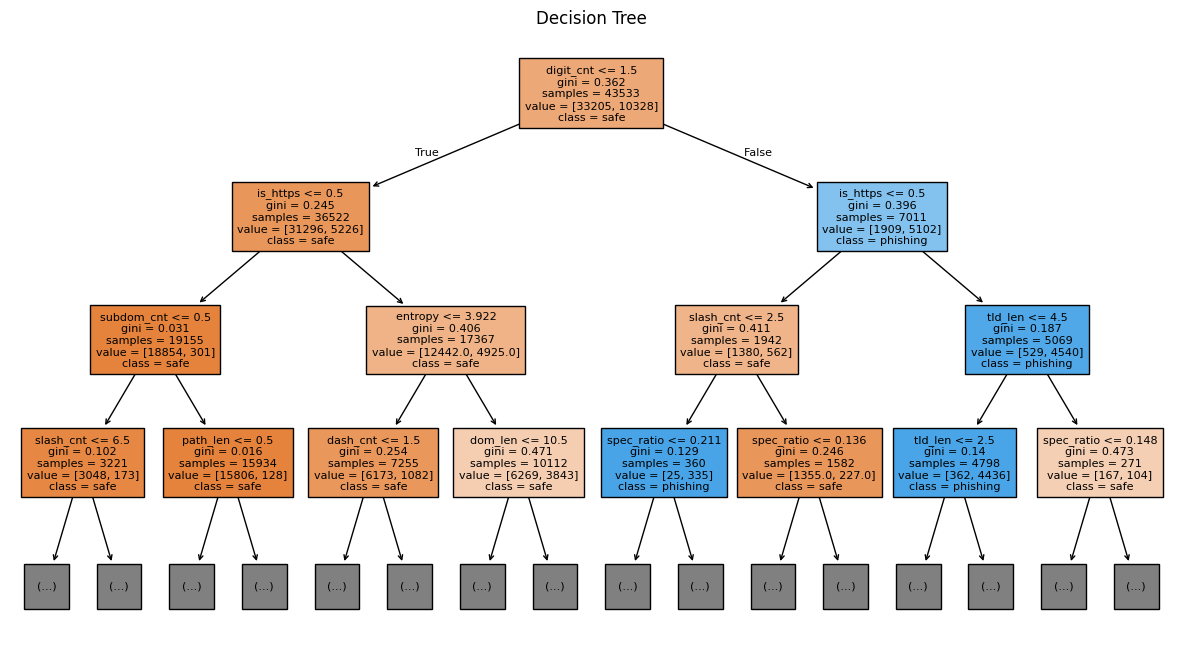

In [34]:
plt.figure(figsize = (15, 8))
plot_tree(tree, max_depth=3, feature_names=X.columns, class_names=["safe", "phishing"], filled=True, fontsize=8)
plt.title("Decision Tree")
plt.show()

Таким чином, дерево добре інтерпретується, проте одне дерево обмеженої глибини гірше апроксимує складну межу між класами, ніж інші моделі.

# **Support Vector Machine (SVM)**

Гіперпараметри C та gamma підбирали за допомогою GridSearchCV із 3-кратною крос-валідацією та оцінкою за F1 на сітці 5х5.

In [35]:
param_grid = {'C': [0.1, 1, 10, 100, 1000], 'gamma': [1,0.1,0.01,0.001,0.0001], 'kernel': ['rbf']}

In [37]:
svm_grid = GridSearchCV(SVC(), param_grid, cv=3, scoring="f1", refit=False)

Пошук виконуємо на підвибірці розміром 30% від тренувальних даних, оскільки час навчання SVM швидко зростає зі збільшенням кількості об'єктів, тому повний перебір комбінацій на всьому наборі був би дуже тривалим.

In [41]:
X_grid, _, y_grid, _ = train_test_split(X_train_scaled, y_train, train_size=0.3, random_state=42, stratify=y_train)

In [42]:
svm_grid.fit(X_grid, y_grid)

GridSearchCV(cv=3, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                         'kernel': ['rbf']},
             refit=False, scoring='f1')

Найкращими виявилися C = 10 та gamma = 0.1.

In [43]:
svm_grid.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [45]:
svm = SVC(**svm_grid.best_params_)

In [46]:
svm.fit(X_train_scaled, y_train)

SVC(C=10, gamma=0.1)

In [47]:
y_pred = svm.predict(X_test_scaled)

На тестовій вибірці модель SVM показала accuracy 0.96, precision для фішингу 0.93, recall=0.88 та F1=0.91.

In [48]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      8302
           1       0.93      0.88      0.91      2582

    accuracy                           0.96     10884
   macro avg       0.95      0.93      0.94     10884
weighted avg       0.96      0.96      0.96     10884



Матриця помилок визначила, що правильно класифіковано 10 420 об'єкти, тоді як помилок лише 464, з яких 160 є хибними тривогами (FP), а 304 є пропущеним фішингом (FN). Модель SVM показала високі значення precision та recall, вказуючи на те, що її перевага не є наслідком компромісу між цими показниками.

In [49]:
print(confusion_matrix(y_test, y_pred))

[[8142  160]
 [ 304 2278]]


# **Random Forest**

In [75]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [77]:
y_pred = rf.predict(X_test)

На тестовій вибірці модель Random Forest показала accuracy 0.95, precision для фішингу 0.92, recall=0.88 та F1=0.90.

In [78]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      8302
           1       0.92      0.88      0.90      2582

    accuracy                           0.95     10884
   macro avg       0.94      0.93      0.93     10884
weighted avg       0.95      0.95      0.95     10884



Матриця помилок визначила, що правильно класифіковано 10 361 з 10 884 об'єктів, тоді як помилок було 523, з яких 207 є хибними тривогами (FP), а 316 є пропущеним фішингом (FN).

In [79]:
print(confusion_matrix(y_test, y_pred))

[[8095  207]
 [ 316 2266]]


Важливість ознак за feature_importances_ показує, що найбільший внесок роблять entropy, is_https, digit_ratio, dom_len та digit_cnt. Найменш інформативними виявилися is_ip, amp_cnt, under_cnt та qm_cnt, оскыльки такі символи або трапляються дуже рідко, або майже однаково розподілені між класами.

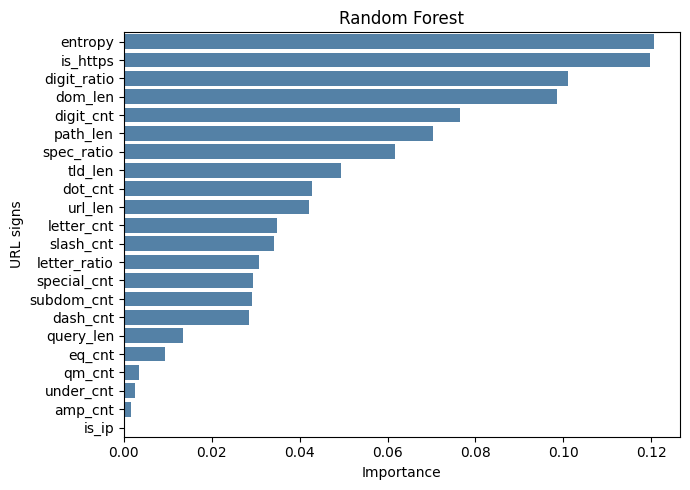

In [80]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
sns.barplot(x=importances.values, y=importances.index, color="steelblue")
plt.title("Random Forest")
plt.xlabel("Importance")
plt.ylabel("URL signs")
plt.tight_layout()
plt.show()

In [81]:
print(f"TOP-5 most important signs:\n{importances.head(5)}")

TOP-5 most important signs:
entropy        0.120509
is_https       0.119605
digit_ratio    0.101100
dom_len        0.098563
digit_cnt      0.076422
dtype: float64


# **AdaBoost**

In [71]:
ada = AdaBoostClassifier(n_estimators=100, learning_rate=1.0, random_state=42)
ada.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [72]:
y_pred = ada.predict(X_test)

Модель AdaBoost показала найгірший результат серед усіх п'яти методів, визначивши accuracy 0.92, precision для фішингу 0.86, recall=0.77 та F1=0.81.

In [73]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      8302
           1       0.86      0.77      0.81      2582

    accuracy                           0.92     10884
   macro avg       0.90      0.86      0.88     10884
weighted avg       0.91      0.92      0.91     10884



Матриця помилок визначила, що правильно класифіковано 9 967 об'єктів, тоды як помилок було 917. Причина поганого результату полягає в тому, що за замовчуванням AdaBoost використовує дуже прості базові класифікатори, тоді як набір даних містить складні взаємодії між ознаками та незбалансовані класи. Наступні класифікатори зосереджуються на найскладніших об'єктах, серед яких багато шуму та викидів, що знижує якість.

In [74]:
print(confusion_matrix(y_test, y_pred))

[[7991  311]
 [ 606 1976]]


Порівняння п'яти класифікаторів на тестовій вибірці з 10 884 об'єктів визначило наступний рейтинг за значенням F1 для класу «фішинг»:
1. SVM
2. Random Forest
3. kNN
4. Decision Tree
5. AdaBoost

За кількістю помилок рейтинг моделей не змінюється:
1. SVM - 464 помилки
2. Random Forest - 523 помилки
3. kNN - 529 помилки
4. Decision Tree - 662 помилки
5. AdaBoost - 917 помилки

In [84]:
models = {
    "kNN": (knn, X_test_scaled),
    "Decision Tree": (tree, X_test),
    "SVM": (svm, X_test_scaled),
    "Random Forest": (rf, X_test),
    "AdaBoost": (ada, X_test),
}

rows = []
for name, (m, Xt) in models.items():
    p = m.predict(Xt)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    })

results = pd.DataFrame(rows)
print(results.round(4))

           Model  Accuracy  Precision  Recall      F1
0            kNN    0.9514     0.9171  0.8741  0.8951
1  Decision Tree    0.9392     0.8993  0.8373  0.8672
2            SVM    0.9574     0.9344  0.8823  0.9076
3  Random Forest    0.9519     0.9163  0.8776  0.8965
4       AdaBoost    0.9157     0.8640  0.7653  0.8117


Таким чином, найкращою моделлю для цього набору даних є SVM з RBF-ядром (C = 10, gamma = 0,1). Вона має найвищі значення всіх метрик: accuracy = 0.9574, precision фішингу 0.9344, recall = 0.8823 та F1 = 0.9076. У неї найменше хибних тривог (160) та пропущеного фішингу (304).

Така перевага пояснюється кількома причинами:
1. RBF-ядро дозволяє будувати гнучку нелінійну межу між класами, тоді як ознаки URL (ентропія, частка цифр, довжини, наявність HTTPS) взаємодіють нелінійно.
2. Дані були стандартизовані, що для методу, який працює з відстанями, є принципово важливим.
3. Гіперпараметри було підібрано за F1 за допомогою GridSearchCV, тоді як Random Forest та AdaBoost використовували значення за замовчуванням.